# Laboratorio: curvas de nivel a partir de un ráster de elevación (.tif)

**Asignatura:** Ciencias de datos geoespaciales  
**Tipo de actividad:** guía de laboratorio práctica  
**Duración estimada:** 2 a 3 horas  

---

## Propósito

Vas a transformar un **Modelo Digital de Elevación (DEM)** en formato GeoTIFF (`.tif`) en **curvas de nivel**: líneas que unen puntos de igual altura. Es una tarea muy común en agronomía: sirve para planificar riego por surcos, trazar terrazas y camellones en contorno, delimitar zonas de escorrentía, diseñar caminos prediales o simplemente leer el relieve de un predio.

Al final del laboratorio tendrás tus curvas en **varios formatos listos para descargar** (GeoPackage, Shapefile, GeoJSON, KML para Google Earth, DXF en 3D para CAD, CSV, y un mapa en PNG/PDF).

## Resultados de aprendizaje

Al terminar, deberías ser capaz de:

1. Obtener un DEM, ya sea **tu propio `.tif`** o **descargándolo** desde una fuente abierta (Copernicus DEM GLO-30).
2. Revisar un DEM antes de usarlo: sistema de referencia (CRS), resolución, valores *NoData* y rango de alturas.
3. Reproyectar el DEM a un sistema **métrico** (UTM) y justificar por qué es necesario.
4. Elegir una **equidistancia** coherente con la resolución y la exactitud del DEM.
5. Generar curvas de nivel con **GDAL** (`ContourGenerateEx`) desde Python y entender su equivalente en la terminal (`gdal_contour`).
6. Clasificar curvas **maestras** e **intermedias**, calcular longitudes y hacer un mapa.
7. **Exportar y descargar** los resultados en el formato adecuado para cada usuario.

## Estructura de la guía

| Parte | Contenido |
|---|---|
| 0 | Preparar el entorno |
| 1 | Parámetros del laboratorio |
| 2 | Obtener el DEM (3 opciones) |
| 3 | Revisar el DEM |
| 4 | Reproyectar a UTM |
| 5 | Elegir la equidistancia |
| 6 | Generar las curvas con GDAL |
| 7 | Mapa final |
| 8 | Exportar en varios formatos |
| 9 | Descargar los resultados |
| 10 | Extensión: pisos altitudinales (polígonos) |
| 11 | Problemas frecuentes, ejercicios y preguntas |

> **Cómo usar esta guía:** ejecuta las celdas **en orden**, de arriba hacia abajo (`Shift + Enter`). Antes de cada celda de código hay una explicación de lo que hace y un enlace a la documentación oficial. Lee la explicación **antes** de ejecutar: el objetivo no es solo obtener las curvas, sino entender cada decisión.

### Repaso rápido: ¿qué hace el computador para dibujar una curva?

Un DEM es una grilla: cada celda guarda **una** altura (la del centro de la celda). Una curva de nivel de, por ejemplo, 650 m casi nunca pasa exactamente por el centro de una celda; pasa **entre** celdas. El algoritmo más usado, llamado ***marching squares*** (cuadrados que avanzan), hace lo siguiente:

1. Marca cada celda como **sobre** o **bajo** el nivel buscado.
2. Recorre la grilla mirando **bloques de 2 × 2 celdas**. Si en un bloque hay celdas sobre y bajo el nivel, la curva lo atraviesa.
3. Ubica el punto exacto de cruce en cada borde mediante **interpolación lineal**. Por ejemplo, entre 640 m y 660 m, la curva de 650 m queda justo a mitad de camino.
4. **Encadena** los segmentos de bloques vecinos para formar líneas continuas.

GDAL aplica esta idea. Por eso las curvas solo pueden ser tan buenas como el DEM: **el algoritmo no inventa detalle que la grilla no tiene**.

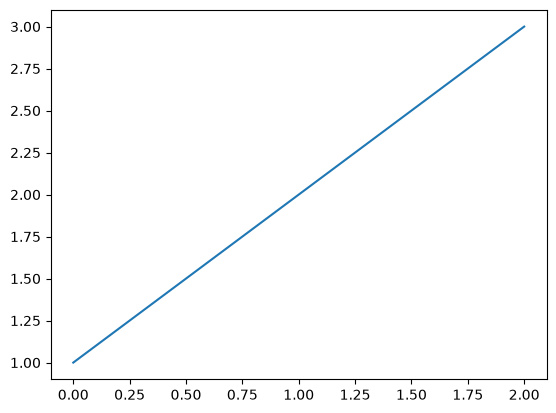

In [1]:
import matplotlib.pyplot as plt
plt.plot([1, 2, 3]); plt.show()


---
## Parte 0. Preparar el entorno

### 0.1 Instalar librerías (solo si te faltan)

Este laboratorio usa:

| Librería | Para qué la usamos |
|---|---|
| [GDAL](https://gdal.org/en/stable/api/python/index.html) (`osgeo`) | Descargar y recortar el DEM, reproyectar, sombreado y **curvas de nivel** |
| [rasterio](https://rasterio.readthedocs.io/) | Leer el ráster como arreglo NumPy, junto con su georreferencia |
| [geopandas](https://geopandas.org/) | Manejar las curvas como tabla con geometría y exportarlas |
| [matplotlib](https://matplotlib.org/) | Mapas y gráficos |

- **Google Colab:** GDAL, rasterio y geopandas ya vienen instalados. Si falta alguna, quita el `#` de la línea `%pip` y ejecuta la celda.
- **Computador local (recomendado: conda):** en una terminal, ejecuta `conda install -c conda-forge gdal rasterio geopandas matplotlib`. Instalar GDAL con `pip` en Windows suele dar problemas; conda lo resuelve.

In [2]:
# Quita el "#" de la siguiente línea solo si te falta alguna librería y reinicia el kernel.
# %pip install rasterio geopandas matplotlib

### 0.2 Importar librerías

Importamos todo al inicio, en orden alfabético, para que sea fácil ver de qué depende el notebook. También:

- [`gdal.UseExceptions()`](https://gdal.org/en/stable/api/python_gotchas.html) hace que GDAL **lance errores de Python** en vez de fallar en silencio devolviendo `None`.
- `EN_COLAB` detecta si estamos en Google Colab. Lo usamos más adelante para elegir cómo subir y descargar archivos.

> Si una línea `import` falla con `ModuleNotFoundError`, vuelve a la celda 0.1.

In [3]:
import math
import shutil
import sys
from pathlib import Path

import geopandas as gpd
from IPython.display import FileLink, display
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
from osgeo import gdal, ogr, osr
import pandas as pd
import rasterio
from rasterio.plot import plotting_extent
import shapely

gdal.UseExceptions()
# Acelera la lectura de archivos remotos: GDAL no intentará listar la "carpeta" del servidor
gdal.SetConfigOption("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")

# Escala de colores para el relieve: "terrain" sin su tramo azul, para que
# las zonas bajas del DEM no parezcan mar
TERRENO = LinearSegmentedColormap.from_list(
    "terreno_sin_mar", plt.cm.terrain(np.linspace(0.25, 1, 256))
)

EN_COLAB = "google.colab" in sys.modules
print(f"GDAL {gdal.__version__} | rasterio {rasterio.__version__} | geopandas {gpd.__version__}")
print("Entorno:", "Google Colab" if EN_COLAB else "Jupyter / VS Code local")

GDAL 3.12.3 | rasterio 1.4.4 | geopandas 1.2.0
Entorno: Jupyter / VS Code local


---
## Parte 1. Parámetros del laboratorio

Concentramos **todas las decisiones** en una sola celda. Así, para repetir el laboratorio con otro predio u otra equidistancia, basta con cambiar esta celda y volver a ejecutar todo (*Run All*).

| Parámetro | Qué significa | Valor por defecto |
|---|---|---|
| `FUENTE_DEM` | `"descargar"`: baja el Copernicus DEM de la zona `BBOX`. `"local"`: usa tu propio `.tif` | `"descargar"` |
| `RUTA_DEM_LOCAL` | Ruta de tu `.tif` si `FUENTE_DEM = "local"` | `datos/mi_dem.tif` |
| `BBOX` | Zona de estudio en grados (lon mín, lat mín, lon máx, lat máx), en WGS84 | Valle y precordillera de Pirque (RM), unos 7 × 9 km |
| `EPSG_SALIDA` | CRS métrico de trabajo. `None` calcula la zona UTM automáticamente | `None` |
| `RESOLUCION_M` | Tamaño de celda tras reproyectar, en metros. `None` deja que GDAL lo estime | `30` |
| `EQUIDISTANCIA` | Diferencia de altura entre curvas consecutivas, en metros | `50` |
| `FACTOR_MAESTRA` | Cada cuántas curvas hay una maestra (4 × 50 m = maestras cada 200 m) | `4` |
| `NIVEL_BASE` | Altura desde la que se cuentan las curvas (casi siempre 0) | `0` |

> **Consejo:** para encontrar el `BBOX` de tu zona, abre [bboxfinder.com](http://bboxfinder.com), dibuja un rectángulo y copia las coordenadas en formato *lon/lat*. Mantén zonas pequeñas (unos 10 × 10 km) mientras aprendes.

In [4]:
# --- Carpetas de trabajo ---
CARPETA_DATOS = Path("datos")
CARPETA_SALIDAS = Path("salidas_lab_curvas")
CARPETA_DATOS.mkdir(exist_ok=True)
CARPETA_SALIDAS.mkdir(exist_ok=True)

# --- Fuente del DEM: "descargar" o "local" ---
FUENTE_DEM = "descargar"
RUTA_DEM_LOCAL = CARPETA_DATOS / "mi_dem.tif"

# --- Zona de estudio (solo se usa si FUENTE_DEM = "descargar") ---
# (lon_min, lat_min, lon_max, lat_max) en grados decimales WGS84
BBOX = (-70.56, -33.70, -70.48, -33.62)

# --- Sistema de referencia y resolución de trabajo ---
EPSG_SALIDA = None      # p. ej. 32719 (UTM 19 S, Chile central); None = automático
RESOLUCION_M = 30       # metros; None = que GDAL lo decida

# --- Curvas de nivel ---
EQUIDISTANCIA = 50      # m entre curvas
FACTOR_MAESTRA = 4      # cada cuántas curvas una es maestra
NIVEL_BASE = 0          # m

# --- Rutas de archivos intermedios ---
RUTA_DEM_GEO = CARPETA_DATOS / "dem_geograficas.tif"
RUTA_DEM_UTM = CARPETA_DATOS / "dem_utm.tif"
RUTA_SOMBRA = CARPETA_DATOS / "sombreado.tif"

---
## Parte 2. Obtener el DEM

Tienes **tres opciones**. Elige **una** según tu situación:

| Opción | Cuándo usarla | Qué necesitas |
|---|---|---|
| **A. Tu propio `.tif`** | Ya tienes un DEM (de un dron, del curso, de un portal) | El archivo `.tif` |
| **B. Descarga recortada desde la nube** (recomendada) | Quieres un DEM de cualquier zona del mundo sin bajar archivos grandes | Internet y un `BBOX` |
| **C. Descarga de la tesela completa** | Trabajarás varias veces en la misma zona o tendrás mala conexión después | Internet (unos 20 a 40 MB por tesela) |

### Sobre la fuente: Copernicus DEM GLO-30

El [Copernicus DEM](https://dataspace.copernicus.eu/explore-data/data-collections/copernicus-contributing-missions/collections-description/COP-DEM) es un modelo **digital de superficie** (DSM) global, con celdas de **1 segundo de arco (unos 30 m)** y una exactitud vertical absoluta **menor a 4 m (LE90)** en la mayor parte del mundo. Está publicado de forma abierta en [AWS (Registry of Open Data)](https://registry.opendata.aws/copernicus-dem/) como **Cloud Optimized GeoTIFF (COG)**: un `.tif` organizado internamente en bloques, lo que permite **leer solo el pedazo que necesitamos** a través de internet.

Se distribuye en **teselas de 1° × 1°** cuyo nombre indica la **esquina suroeste**: la tesela `S34_00_W071_00` cubre de 34° S a 33° S y de 71° O a 70° O.

> **Ojo agronómico:** al ser un **DSM**, el Copernicus DEM incluye la altura de árboles, huertos frutales y edificios. En un huerto adulto de nogales o en un bosque, las curvas "suben" sobre el dosel. Para diseño fino de riego o de terrazas se necesita un **DTM** (terreno desnudo), por ejemplo de LiDAR o de un levantamiento con dron y puntos de control.

> **Licencia:** cita la fuente como *"Copernicus DEM GLO-30 © DLR e.V. 2010-2014 y © Airbus Defence and Space GmbH 2014-2018, proporcionado bajo COPERNICUS por la Unión Europea y la ESA"*.

### Opción A. Usar tu propio archivo `.tif`

1. En la celda de parámetros, cambia `FUENTE_DEM = "local"`.
2. Pon tu archivo en la carpeta `datos/` y ajusta `RUTA_DEM_LOCAL` con su nombre.
3. **En Google Colab**, la celda de abajo abre un botón para **subir** el archivo desde tu computador con [`files.upload()`](https://colab.research.google.com/notebooks/io.ipynb). En Colab los archivos subidos se borran al cerrar la sesión.

Requisitos mínimos de tu `.tif`: **una banda** de elevación, con **CRS definido**. Si no tiene CRS, GDAL no sabrá dónde está ni en qué unidades se mide, y no podremos reproyectarlo.

In [5]:
if FUENTE_DEM == "local":
    if EN_COLAB and not RUTA_DEM_LOCAL.exists():
        from google.colab import files
        print("Selecciona tu archivo .tif...")
        subidos = files.upload()                      # abre el selector de archivos
        nombre = next(iter(subidos))
        RUTA_DEM_LOCAL = CARPETA_DATOS / nombre
        Path(nombre).replace(RUTA_DEM_LOCAL)          # lo movemos a datos/
    if not RUTA_DEM_LOCAL.exists():
        raise FileNotFoundError(f"No encuentro {RUTA_DEM_LOCAL}. Revisa la ruta en la Parte 1.")
    RUTA_DEM_ENTRADA = RUTA_DEM_LOCAL
    print("Usaremos tu DEM:", RUTA_DEM_ENTRADA)
else:
    print("FUENTE_DEM = 'descargar' → salta a la Opción B (esta celda no hace nada).")

FUENTE_DEM = 'descargar' → salta a la Opción B (esta celda no hace nada).


### Opción B. Descargar solo la zona de estudio (recortada desde la nube)

Esta es la opción más eficiente. Tiene tres pasos:

1. **Calcular qué teselas** de 1° × 1° toca el `BBOX`. Si tu zona cruza un grado entero de latitud o longitud, necesitará más de una.
2. Unirlas en un **mosaico virtual** con [`gdal.BuildVRT`](https://gdal.org/en/stable/api/python/utilities.html#osgeo.gdal.BuildVRT). Un VRT es un pequeño archivo de texto que *apunta* a las teselas remotas, sin copiarlas. El prefijo [`/vsicurl/`](https://gdal.org/en/stable/user/virtual_file_systems.html#vsicurl-http-https-ftp-files-random-access) le dice a GDAL que lea por HTTP.
3. **Recortar** al `BBOX` con [`gdal.Translate`](https://gdal.org/en/stable/api/python/utilities.html#osgeo.gdal.Translate) y la opción `projWin`. GDAL descarga **solo los bloques** del COG que caen en la zona, normalmente unos pocos cientos de KB.

> `projWin` usa el orden **(x mín, y máx, x máx, y mín)**, es decir, la esquina superior izquierda y luego la inferior derecha. Es un error frecuente pasarlo en el orden del `BBOX`.

In [6]:
def teselas_copernicus(bbox):
    # Devuelve las URL /vsicurl/ de las teselas Copernicus GLO-30 que cubren el bbox.
    lon_min, lat_min, lon_max, lat_max = bbox
    urls = []
    for lat in range(math.floor(lat_min), math.ceil(lat_max)):
        for lon in range(math.floor(lon_min), math.ceil(lon_max)):
            ns = "N" if lat >= 0 else "S"
            ew = "E" if lon >= 0 else "W"
            nombre = f"Copernicus_DSM_COG_10_{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM"
            urls.append(f"/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com/{nombre}/{nombre}.tif")
    return urls


if FUENTE_DEM == "descargar":
    urls = teselas_copernicus(BBOX)
    print(f"Teselas necesarias: {len(urls)}")
    for u in urls:
        print("  ", u.split("/")[-1])

    lon_min, lat_min, lon_max, lat_max = BBOX
    mosaico = gdal.BuildVRT("/vsimem/mosaico.vrt", urls)       # mosaico virtual en memoria
    gdal.Translate(
        str(RUTA_DEM_GEO),
        mosaico,
        projWin=[lon_min, lat_max, lon_max, lat_min],          # (x mín, y máx, x máx, y mín)
        creationOptions=["COMPRESS=DEFLATE", "TILED=YES"],
    )
    mosaico = None                                             # cierra el VRT
    RUTA_DEM_ENTRADA = RUTA_DEM_GEO
    print(f"\nDEM recortado guardado en: {RUTA_DEM_ENTRADA} "
          f"({RUTA_DEM_ENTRADA.stat().st_size / 1024:.0f} KB)")

Teselas necesarias: 1
   Copernicus_DSM_COG_10_S34_00_W071_00_DEM.tif

DEM recortado guardado en: datos\dem_geograficas.tif (276 KB)


### Opción C (opcional). Descargar la tesela completa

Si prefieres tener la tesela entera en tu disco (por ejemplo, para trabajar sin conexión), cambia `DESCARGAR_TESELA_COMPLETA = True`. La celda usa [`urllib.request.urlretrieve`](https://docs.python.org/3/library/urllib.request.html#urllib.request.urlretrieve), de la biblioteca estándar de Python. Luego puedes usarla como en la **Opción A** (`FUENTE_DEM = "local"` y `RUTA_DEM_LOCAL` apuntando al archivo).

> Fuentes alternativas por portal web: [OpenTopography](https://portal.opentopography.org/) (Copernicus, SRTM, ALOS, NASADEM con recorte por zona) y [USGS EarthExplorer](https://earthexplorer.usgs.gov/) (SRTM).

In [7]:
DESCARGAR_TESELA_COMPLETA = False

if DESCARGAR_TESELA_COMPLETA:
    import urllib.request
    for u in teselas_copernicus(BBOX):
        url_http = u.replace("/vsicurl/", "")
        destino = CARPETA_DATOS / url_http.split("/")[-1]
        if destino.exists():
            print("Ya existe:", destino)
            continue
        print("Descargando", destino.name, "...")
        urllib.request.urlretrieve(url_http, destino)
        print(f"  listo ({destino.stat().st_size / 1e6:.1f} MB)")
else:
    print("Opción C desactivada.")

Opción C desactivada.


---
## Parte 3. Revisar el DEM antes de usarlo

**Nunca contornees un DEM sin mirarlo antes.** La mayoría de los errores con curvas de nivel vienen de saltarse este paso. Revisa lo siguiente:

| Pregunta | Por qué importa |
|---|---|
| ¿Qué **CRS** tiene? ¿Grados o metros? | En grados, la equidistancia y las longitudes no tienen sentido métrico |
| ¿Qué **resolución** (tamaño de celda)? | Limita el detalle y la equidistancia razonable |
| ¿Tiene valor **NoData** definido? | Si no, valores como -32768 o -9999 generan curvas falsas en "pozos" |
| ¿Qué **rango de alturas** tiene? | Para saber cuántas curvas saldrán y detectar valores absurdos |
| ¿Cuántas **bandas**? | Un DEM debe tener 1 banda de elevación |

Usamos [`rasterio.open`](https://rasterio.readthedocs.io/en/stable/api/rasterio.html#rasterio.open) para leer los metadatos y [`read(masked=True)`](https://rasterio.readthedocs.io/en/stable/topics/masks.html), que oculta automáticamente las celdas NoData.

In [8]:
def describir_dem(ruta):
    with rasterio.open(ruta) as src:
        datos = src.read(1, masked=True)
        print(f"Archivo        : {ruta}")
        print(f"CRS            : {src.crs}  (¿geográfico? {src.crs.is_geographic})")
        print(f"Tamaño         : {src.width} columnas × {src.height} filas, {src.count} banda(s)")
        print(f"Tamaño de celda: {src.res[0]:.6g} × {src.res[1]:.6g} {src.crs.linear_units if src.crs.is_projected else 'grados'}")
        print(f"Tipo de dato   : {src.dtypes[0]}")
        print(f"NoData         : {src.nodata}")
        print(f"Celdas válidas : {datos.count()} de {datos.size} ({100 * datos.count() / datos.size:.1f} %)")
        print(f"Altura mín/máx : {datos.min():.1f} / {datos.max():.1f}")
        print(f"Altura media   : {datos.mean():.1f}")


describir_dem(RUTA_DEM_ENTRADA)

Archivo        : datos\dem_geograficas.tif
CRS            : EPSG:4326  (¿geográfico? True)
Tamaño         : 289 columnas × 289 filas, 1 banda(s)
Tamaño de celda: 0.000277778 × 0.000277778 grados
Tipo de dato   : float32
NoData         : None
Celdas válidas : 83521 de 83521 (100.0 %)
Altura mín/máx : 655.5 / 2042.4
Altura media   : 954.3


**Interpreta la salida antes de seguir:**

- Si el CRS es geográfico (EPSG:4326), el tamaño de celda aparece en **grados** (≈ 0,000278° = 1"). En la Parte 4 lo pasamos a metros.
- Si `NoData` es `None` pero ves mínimos extraños (−32768, −9999, 0 en plena cordillera), tendrás que definirlo. Lo hacemos en la Parte 4 con `srcNodata`.
- Compara el rango de alturas con lo que conoces de la zona. En la zona de ejemplo (Pirque), el fondo del valle agrícola está cerca de 650 m y las cumbres de la precordillera superan los 2.000 m.

### 3.1 Ver el DEM

Un vistazo rápido con [`matplotlib.pyplot.imshow`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html). Busca bandas, "agujeros", bordes raros o valores que no correspondan al relieve esperado.

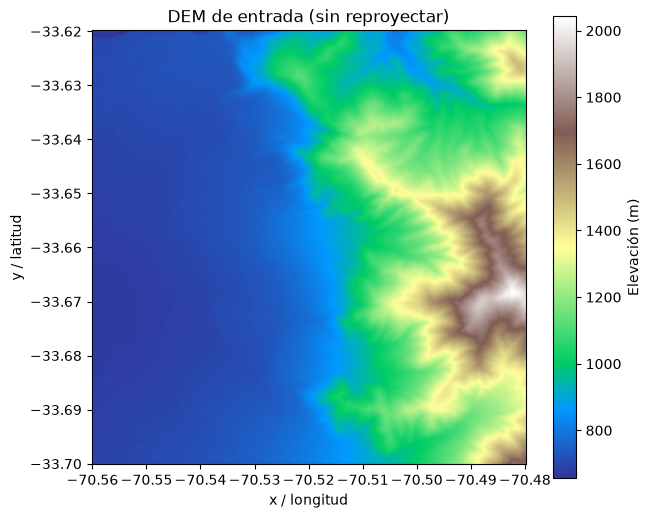

In [9]:
with rasterio.open(RUTA_DEM_ENTRADA) as src:
    dem_entrada = src.read(1, masked=True)
    extension = plotting_extent(src)

fig, ax = plt.subplots(figsize=(7, 6))
img = ax.imshow(dem_entrada, cmap=TERRENO, extent=extension)
fig.colorbar(img, ax=ax, label="Elevación (m)")
ax.set_title("DEM de entrada (sin reproyectar)")
ax.set_xlabel("x / longitud")
ax.set_ylabel("y / latitud")
plt.show()

---
## Parte 4. Reproyectar a un sistema métrico (UTM)

### ¿Por qué reproyectar?

- La **equidistancia** se mide en metros de altura. Eso no depende del CRS, pero las **longitudes**, **pendientes** y **áreas** sí necesitan coordenadas en metros.
- En grados, una celda no es cuadrada en el terreno: a 33° S, 1" de longitud mide unos 26 m y 1" de latitud unos 31 m. Esto deforma el sombreado y las mediciones.
- Las curvas exportadas en UTM se pueden llevar directamente a CAD o GPS con coordenadas métricas.

### ¿Qué zona UTM?

La zona se calcula con la longitud: `zona = floor((lon + 180) / 6) + 1`. En el hemisferio sur el EPSG es `327XX` y en el norte `326XX`. Chile continental está entre las zonas **18 S** (EPSG:32718) y **19 S** (EPSG:32719).

### Herramienta

[`gdal.Warp`](https://gdal.org/en/stable/api/python/utilities.html#osgeo.gdal.Warp) reproyecta y remuestrea. Usamos **remuestreo bilineal**, porque la elevación es una variable **continua**. *Nearest neighbour* produciría "escalones" que se verían como curvas dentadas.

In [10]:
def epsg_utm(lon, lat):
    # Código EPSG de la zona UTM WGS84 que contiene el punto (lon, lat).
    zona = int((lon + 180) // 6) + 1
    return (32700 if lat < 0 else 32600) + zona


# Centro del DEM en grados, para estimar la zona UTM
info = gdal.Info(str(RUTA_DEM_ENTRADA), format="json")
anillo = np.array(info["wgs84Extent"]["coordinates"][0])
lon_c, lat_c = anillo[:, 0].mean(), anillo[:, 1].mean()

epsg = EPSG_SALIDA or epsg_utm(lon_c, lat_c)
print(f"Centro de la zona: lon {lon_c:.4f}, lat {lat_c:.4f}  →  EPSG:{epsg}")

opciones_warp = dict(
    dstSRS=f"EPSG:{epsg}",
    resampleAlg="bilinear",
    dstNodata=-9999,
    # srcNodata=-32768,   # quita el "#" si tu DEM no tiene NoData definido y usa otro valor (p. ej. -32768)
    creationOptions=["COMPRESS=DEFLATE", "TILED=YES"],
)
if RESOLUCION_M:
    opciones_warp.update(xRes=RESOLUCION_M, yRes=RESOLUCION_M, targetAlignedPixels=True)

gdal.Warp(str(RUTA_DEM_UTM), str(RUTA_DEM_ENTRADA), **opciones_warp)
print()
describir_dem(RUTA_DEM_UTM)

Centro de la zona: lon -70.5280, lat -33.6520  →  EPSG:32719

Archivo        : datos\dem_utm.tif
CRS            : EPSG:32719  (¿geográfico? False)
Tamaño         : 252 columnas × 300 filas, 1 banda(s)
Tamaño de celda: 30 × 30 metre
Tipo de dato   : float32
NoData         : -9999.0
Celdas válidas : 73647 de 75600 (97.4 %)
Altura mín/máx : 657.9 / 2040.9
Altura media   : 954.2


### 4.1 Sombreado (*hillshade*) para ver el relieve

Un sombreado simula la iluminación del terreno con un sol en el noroeste (azimut 315°, altura 45°). Nos servirá de **fondo** para los mapas, porque el ojo entiende el relieve mucho mejor así que con una rampa de colores.

Usamos [`gdal.DEMProcessing`](https://gdal.org/en/stable/api/python/utilities.html#osgeo.gdal.DEMProcessing), equivalente en Python al programa [`gdaldem hillshade`](https://gdal.org/en/stable/programs/gdaldem.html).

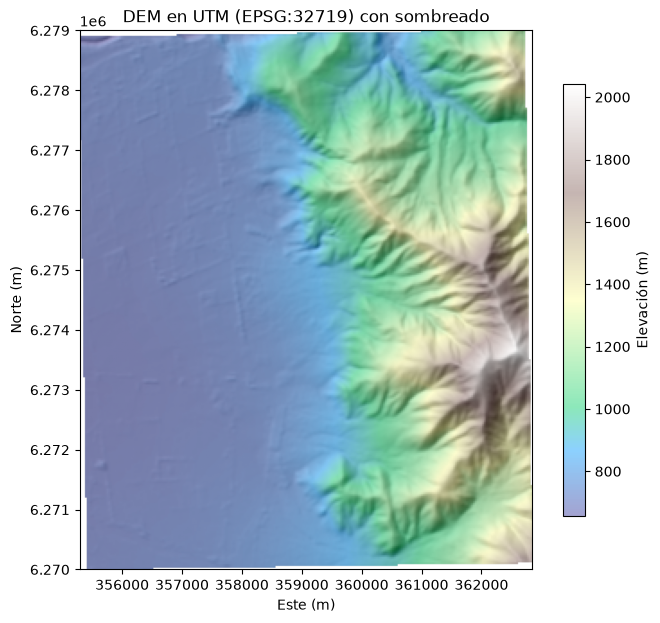

In [11]:
gdal.DEMProcessing(str(RUTA_SOMBRA), str(RUTA_DEM_UTM), "hillshade",
                   azimuth=315, altitude=45, computeEdges=True)

with rasterio.open(RUTA_DEM_UTM) as src:
    dem = src.read(1, masked=True)
    extension = plotting_extent(src)
with rasterio.open(RUTA_SOMBRA) as src:
    sombra = src.read(1, masked=True)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(sombra, cmap="gray", extent=extension)
img = ax.imshow(dem, cmap=TERRENO, alpha=0.45, extent=extension)
fig.colorbar(img, ax=ax, label="Elevación (m)", shrink=0.8)
ax.set_title(f"DEM en UTM (EPSG:{epsg}) con sombreado")
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")
plt.show()

---
## Parte 5. Elegir la equidistancia

La **equidistancia** es la diferencia de altura entre dos curvas consecutivas. Elegirla bien es una decisión técnica, no estética:

- **Si es muy pequeña:** aparecen curvas que reflejan **ruido** del DEM y no relieve real. Su posición tiene un error mayor que la separación entre ellas.
- **Si es muy grande:** se pierde información útil (pequeñas lomas, quebradas suaves).

### Reglas prácticas

1. **Exactitud vertical:** la equidistancia debería ser **al menos 2 veces el error vertical** del DEM. Para Copernicus GLO-30 (< 4 m LE90), eso da **≥ 5 a 10 m**.
2. **Resolución:** con celdas de 30 m, equidistancias de 10 a 20 m son razonables en ladera. En terreno muy plano, un DEM de 30 m simplemente **no permite** curvas de 1 m, por mucho que el software las dibuje.
3. **Propósito:** reconocimiento general del predio (10 a 25 m); diseño de riego o terrazas (0,25 a 1 m, **solo** con DTM de dron o LiDAR).
4. **Maestras:** por convención, una de cada 4 o 5 curvas es maestra (más gruesa y rotulada).

La celda siguiente calcula el **desnivel** y cuántas curvas resultarían con distintas equidistancias.

In [12]:
z_min, z_max = float(dem.min()), float(dem.max())
desnivel = z_max - z_min
print(f"Altura mínima {z_min:.1f} m | máxima {z_max:.1f} m | desnivel {desnivel:.1f} m\n")

tabla = pd.DataFrame({"equidistancia_m": [1, 2, 5, 10, 20, 25, 50]})
tabla["n_curvas_aprox"] = (desnivel // tabla["equidistancia_m"]).astype(int)
tabla["comentario"] = np.select(
    [tabla["equidistancia_m"] < 5, tabla["n_curvas_aprox"] > 150, tabla["n_curvas_aprox"] < 5],
    ["menor al error del DEM: mostraría ruido", "demasiadas curvas: mapa saturado", "muy pocas: se pierde relieve"],
    default="razonable",
)
display(tabla)

maestra = EQUIDISTANCIA * FACTOR_MAESTRA
print(f"Elegida: equidistancia {EQUIDISTANCIA} m, maestras cada {maestra} m "
      f"(≈ {int(desnivel // EQUIDISTANCIA)} curvas)")

Altura mínima 657.9 m | máxima 2040.9 m | desnivel 1383.0 m



,equidistancia_m,n_curvas_aprox,comentario
0,1,1382,menor al error del DEM: mostraría ruido
1,2,691,menor al error del DEM: mostraría ruido
2,5,276,demasiadas curvas: mapa saturado
3,10,138,razonable
4,20,69,razonable
5,25,55,razonable
6,50,27,razonable


Elegida: equidistancia 25 m, maestras cada 100 m (≈ 55 curvas)


---
## Parte 6. Generar las curvas con GDAL

GDAL es el "motor" detrás de QGIS, ArcGIS y casi todo el software SIG. Su programa [`gdal_contour`](https://gdal.org/en/stable/programs/gdal_contour.html) también está disponible desde Python como [`gdal.ContourGenerateEx`](https://gdal.org/en/stable/api/python/raster_api.html#osgeo.gdal.ContourGenerateEx).

**Pasos:**

1. Abrir el DEM y tomar su **banda 1**.
2. Crear un archivo vectorial vacío (GeoPackage) con una **capa de líneas** en el **mismo CRS** del DEM.
3. Crear los **campos** donde GDAL escribirá el identificador (`id`, posición 0) y la altura (`elev`, posición 1).
4. Llamar a `ContourGenerateEx` con las opciones:

| Opción | Equivalente en `gdal_contour` | Significado |
|---|---|---|
| `LEVEL_INTERVAL` | `-i` | Equidistancia |
| `LEVEL_BASE` | `-off` | Nivel base |
| `ELEV_FIELD` | `-a` | **Posición** (índice desde 0) del campo donde se guarda la altura |
| `ID_FIELD` | (automático) | **Posición** del campo identificador |
| `NODATA` | `-snodata` | Valor a ignorar |
| `FIXED_LEVELS` | `-fl` | Lista de alturas específicas (p. ej. la cota de un tranque) |

> **Equivalente en la terminal:**
> `gdal_contour -a elev -i 25 -off 0 datos/dem_utm.tif salidas_lab_curvas/curvas_gdal.gpkg`

In [13]:
ruta_curvas_gdal = CARPETA_SALIDAS / "curvas_gdal.gpkg"
if ruta_curvas_gdal.exists():
    ruta_curvas_gdal.unlink()                      # evita mezclar con una corrida anterior

ds_dem = gdal.Open(str(RUTA_DEM_UTM))
banda = ds_dem.GetRasterBand(1)

ds_vec = ogr.GetDriverByName("GPKG").CreateDataSource(str(ruta_curvas_gdal))
capa = ds_vec.CreateLayer("curvas", srs=ds_dem.GetSpatialRef(), geom_type=ogr.wkbLineString)
capa.CreateField(ogr.FieldDefn("id", ogr.OFTInteger))
capa.CreateField(ogr.FieldDefn("elev", ogr.OFTReal))

opciones = [
    f"LEVEL_INTERVAL={EQUIDISTANCIA}",
    f"LEVEL_BASE={NIVEL_BASE}",
    "ID_FIELD=0",       # ¡ojo! se indica la POSICIÓN del campo (0 = "id"), no su nombre
    "ELEV_FIELD=1",     # posición 1 = "elev"
]
if banda.GetNoDataValue() is not None:
    opciones.append(f"NODATA={banda.GetNoDataValue()}")

gdal.ContourGenerateEx(banda, capa, options=opciones)

ds_vec = None   # cerrar = guardar en disco
ds_dem = None
print("Curvas GDAL guardadas en:", ruta_curvas_gdal)

Curvas GDAL guardadas en: salidas_lab_curvas\curvas_gdal.gpkg


### 6.1 Leer las curvas y clasificarlas

Abrimos el resultado con [`geopandas.read_file`](https://geopandas.org/en/stable/docs/reference/api/geopandas.read_file.html). Cada fila es una línea, con su altura en `elev`. Luego:

- **Clasificamos** como `maestra` las curvas cuya altura (descontando el nivel base) es múltiplo de `EQUIDISTANCIA × FACTOR_MAESTRA`, y el resto como `intermedia`. Usamos `np.isclose` porque las alturas son números decimales, que en el computador pueden quedar como 49,999999 en vez de 50.
- Calculamos la **longitud** de cada curva con [`GeoSeries.length`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoSeries.length.html). Está en metros porque el CRS es UTM.

In [14]:
def clasificar(gdf):
    # Agrega las columnas 'tipo' (maestra/intermedia) y 'long_m'.
    paso_maestra = EQUIDISTANCIA * FACTOR_MAESTRA
    resto = np.mod(gdf["elev"] - NIVEL_BASE, paso_maestra)
    es_maestra = np.isclose(resto, 0) | np.isclose(resto, paso_maestra)
    gdf["tipo"] = np.where(es_maestra, "maestra", "intermedia")
    gdf["long_m"] = gdf.geometry.length.round(1)
    return gdf


curvas_gdal = clasificar(gpd.read_file(ruta_curvas_gdal))
# Control de calidad: si 'elev' viene vacío, las opciones de campos están mal configuradas
assert curvas_gdal["elev"].notna().all(), "Hay curvas sin altura: revisa ELEV_FIELD en la Parte 6"
print(f"Curvas generadas: {len(curvas_gdal)} | CRS: {curvas_gdal.crs}")
display(curvas_gdal.head())
display(curvas_gdal.groupby("tipo")["long_m"].agg(["count", "sum"]).rename(
    columns={"count": "n_lineas", "sum": "longitud_total_m"}))

Curvas generadas: 164 | CRS: EPSG:32719


,id,elev,geometry,tipo,long_m
0,0,800.0,"LINESTRING (360453.648 6278970, 360453.648 627...",maestra,106.0
1,1,1050.0,"LINESTRING (361634.853 6279000, 361634.853 627...",intermedia,176.8
2,2,1175.0,"LINESTRING (362690.585 6279000, 362690.585 627...",intermedia,75.3
3,3,675.0,"LINESTRING (357024.534 6278940, 357024.534 627...",intermedia,238.6
4,4,700.0,"LINESTRING (356427.07 6278910, 356427.07 62788...",maestra,131.6


,n_lineas,longitud_total_m
tipo,,
intermedia,126,517085.1
maestra,38,174171.3


**Pregunta para pensar:** ¿por qué hay **más líneas** que niveles de altura? Pista: una misma altura puede aparecer en varios cerros o quebradas separados, y cada tramo continuo es una línea distinta.

---
## Parte 7. Mapa final

Un buen mapa de curvas sigue las convenciones de la cartografía topográfica:

- **Intermedias** finas y **maestras** más gruesas, ambas en color **sepia o café**.
- **Rótulos de altura** solo en las maestras, para no saturar el mapa.
- Fondo de **sombreado** suave, título, ejes en metros, CRS y fuente.

Para rotular, ponemos el texto en el **punto medio** de cada maestra larga con [`interpolate(0.5, normalized=True)`](https://shapely.readthedocs.io/en/stable/reference/shapely.line_interpolate_point.html). Guardamos con [`savefig`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html) en **PNG** (300 ppp, para informes) y **PDF** (vectorial, para imprimir).

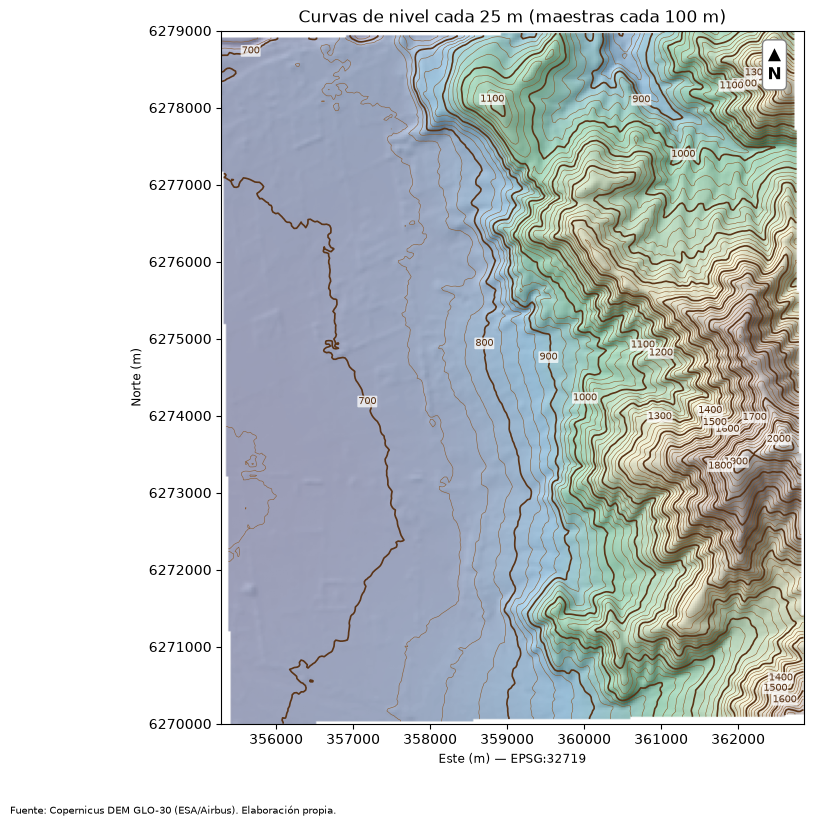

In [15]:
CURVAS_MAPA = curvas_gdal

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(sombra, cmap="gray", extent=extension, alpha=0.8)
ax.imshow(dem, cmap=TERRENO, extent=extension, alpha=0.25)

inter = CURVAS_MAPA[CURVAS_MAPA["tipo"] == "intermedia"]
maes = CURVAS_MAPA[CURVAS_MAPA["tipo"] == "maestra"]
inter.plot(ax=ax, color="#8c5a2b", linewidth=0.4)
maes.plot(ax=ax, color="#5b3416", linewidth=1.2)

# Rótulos en las maestras largas (evita rotular tramos muy cortos)
for _, fila in maes[maes["long_m"] > 500].iterrows():
    p = fila.geometry.interpolate(0.5, normalized=True)
    ax.text(p.x, p.y, f"{fila['elev']:.0f}", fontsize=7, color="#5b3416", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.75))

ax.set_xlim(extension[0], extension[1])
ax.set_ylim(extension[2], extension[3])
ax.set_title(f"Curvas de nivel cada {EQUIDISTANCIA} m (maestras cada {EQUIDISTANCIA * FACTOR_MAESTRA} m)")
ax.set_xlabel(f"Este (m) — EPSG:{epsg}")
ax.set_ylabel("Norte (m)")
ax.ticklabel_format(style="plain")
ax.annotate("▲\nN", xy=(0.95, 0.93), xycoords="axes fraction", ha="center", fontsize=12, weight="bold",
            bbox=dict(boxstyle="round", fc="white", ec="0.5"))
fig.text(0.01, 0.01, "Fuente: Copernicus DEM GLO-30 (ESA/Airbus). Elaboración propia.", fontsize=7)

RUTA_PNG = CARPETA_SALIDAS / "mapa_curvas.png"
RUTA_PDF = CARPETA_SALIDAS / "mapa_curvas.pdf"
fig.savefig(RUTA_PNG, dpi=300, bbox_inches="tight")
fig.savefig(RUTA_PDF, bbox_inches="tight")
plt.show()

---
## Parte 8. Exportar en varios formatos

Cada usuario necesita un formato distinto. Esta tabla resume cuál entregar:

| Formato | Extensión | Ideal para | Detalles |
|---|---|---|---|
| **GeoPackage** | `.gpkg` | QGIS, ArcGIS, archivo de trabajo | **Recomendado.** Un solo archivo, sin límites de nombres de campo |
| **Shapefile** | `.shp` (+ `.shx`, `.dbf`, `.prj`) → `.zip` | Software antiguo, instituciones que lo exigen | Varios archivos: **siempre entrégalos juntos (zip)**. Campos de máx. 10 caracteres |
| **GeoJSON** | `.geojson` | Web, Leaflet, intercambio liviano | Por norma (RFC 7946) va en **WGS84 (EPSG:4326)** |
| **KML** | `.kml` | **Google Earth**, celular, productores | En WGS84 |
| **DXF 3D** | `.dxf` | **AutoCAD**, topografía, diseño de riego | Curvas con **altura Z** y capas *maestra* / *intermedia* |
| **CSV + WKT** | `.csv` | Excel, bases de datos | Geometría como texto (WKT) |
| **Mapa** | `.png` / `.pdf` | Informes y presentaciones | Ya generados en la Parte 7 |
| **DEM recortado** | `.tif` (COG) | Reutilizar el ráster | Cloud Optimized GeoTIFF |

Usamos [`GeoDataFrame.to_file`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.to_file.html) (los formatos vectoriales los escribe GDAL por debajo) y [`to_crs`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.to_crs.html) para pasar a WGS84 cuando corresponde.

Para el **DXF 3D** le damos a cada línea su altura como coordenada Z con [`shapely.force_3d`](https://shapely.readthedocs.io/en/stable/reference/shapely.force_3d.html). Así, al abrirlo en CAD, las curvas quedan a su cota real. El campo especial `Layer` define la capa de CAD.

In [16]:
CURVAS_EXPORTAR = curvas_gdal[["elev", "tipo", "long_m", "geometry"]].copy()
curvas_wgs84 = CURVAS_EXPORTAR.to_crs(4326)
archivos = {}

# 1) GeoPackage (formato de trabajo recomendado)
archivos["gpkg"] = CARPETA_SALIDAS / "curvas.gpkg"
CURVAS_EXPORTAR.to_file(archivos["gpkg"], layer="curvas", driver="GPKG")

# 2) Shapefile, comprimido en .zip (un shapefile son varios archivos)
carpeta_shp = CARPETA_SALIDAS / "curvas_shp"
carpeta_shp.mkdir(exist_ok=True)
CURVAS_EXPORTAR.to_file(carpeta_shp / "curvas.shp", encoding="utf-8")
archivos["shp"] = Path(shutil.make_archive(str(carpeta_shp), "zip", carpeta_shp))

# 3) GeoJSON en WGS84
archivos["geojson"] = CARPETA_SALIDAS / "curvas.geojson"
curvas_wgs84.to_file(archivos["geojson"], driver="GeoJSON")

# 4) KML para Google Earth (el campo "Name" se muestra como etiqueta)
archivos["kml"] = CARPETA_SALIDAS / "curvas.kml"
curvas_wgs84.assign(Name=curvas_wgs84["elev"].map("{:.0f} m".format)).to_file(
    archivos["kml"], driver="KML")

# 5) DXF en 3D para CAD: Z = altura de la curva, una capa por tipo
archivos["dxf"] = CARPETA_SALIDAS / "curvas_3d.dxf"
gpd.GeoDataFrame(
    {"Layer": CURVAS_EXPORTAR["tipo"].values},
    geometry=shapely.force_3d(CURVAS_EXPORTAR.geometry.values, CURVAS_EXPORTAR["elev"].values),
    crs=CURVAS_EXPORTAR.crs,
).to_file(archivos["dxf"], driver="DXF")

# 6) CSV con la geometría en texto WKT
archivos["csv"] = CARPETA_SALIDAS / "curvas.csv"
CURVAS_EXPORTAR.assign(wkt=CURVAS_EXPORTAR.geometry.to_wkt()).drop(columns="geometry").to_csv(
    archivos["csv"], index=False)

# 7) Mapas (creados en la Parte 7)
archivos["png"] = RUTA_PNG
archivos["pdf"] = RUTA_PDF

# 8) DEM reproyectado como Cloud Optimized GeoTIFF
archivos["dem"] = CARPETA_SALIDAS / "dem_utm_cog.tif"
gdal.Translate(str(archivos["dem"]), str(RUTA_DEM_UTM), format="COG",
               creationOptions=["COMPRESS=DEFLATE"])

display(pd.DataFrame(
    [(clave, ruta.name, round(ruta.stat().st_size / 1024, 1)) for clave, ruta in archivos.items()],
    columns=["opcion", "archivo", "tamaño_KB"],
))

,opcion,archivo,tamaño_KB
0,gpkg,curvas.gpkg,628.0
1,shp,curvas_shp.zip,257.1
2,geojson,curvas.geojson,1352.7
3,kml,curvas.kml,1106.9
4,dxf,curvas_3d.dxf,964.4
5,csv,curvas.csv,670.2
6,png,mapa_curvas.png,2222.8
7,pdf,mapa_curvas.pdf,488.4
8,dem,dem_utm_cog.tif,246.8


### 10.1 Verificar lo exportado

**Un archivo exportado no está terminado hasta comprobar que se abre bien.** Volvemos a leer algunos formatos y revisamos el número de líneas y el CRS. También conviene abrir el `.gpkg` en QGIS, el `.kml` en Google Earth y el `.dxf` en un visor CAD.

In [17]:
for clave in ["gpkg", "geojson", "kml", "dxf"]:
    g = gpd.read_file(archivos[clave])
    print(f"{clave:8s} → {len(g):4d} líneas | CRS: {g.crs.to_string() if g.crs else 'sin CRS'} "
          f"| ¿3D? {bool(g.has_z.any())}")

g = gpd.read_file(f"zip://{archivos['shp']}")
print(f"{'shp.zip':8s} → {len(g):4d} líneas | CRS: {g.crs.to_string()} | campos: {list(g.columns)}")

gpkg     →  164 líneas | CRS: EPSG:32719 | ¿3D? False
geojson  →  164 líneas | CRS: EPSG:4326 | ¿3D? False
kml      →  164 líneas | CRS: EPSG:4326 | ¿3D? False
dxf      →  164 líneas | CRS: sin CRS | ¿3D? True
shp.zip  →  164 líneas | CRS: EPSG:32719 | campos: ['elev', 'tipo', 'long_m', 'geometry']


> **¿Por qué el DXF dice "sin CRS"?** El formato DXF **no guarda el sistema de referencia**. Las coordenadas están en UTM (EPSG que usaste), pero quien lo abra debe saberlo. **Anótalo siempre** al entregar el archivo (por ejemplo, en el nombre: `curvas_3d_EPSG32719.dxf`).

---
## Parte 9. Descargar los resultados

Elige qué descargar en la variable `DESCARGAR`:

| Valor | Descarga |
|---|---|
| `"todo"` | Un `.zip` con **todos** los resultados |
| `"gpkg"`, `"shp"`, `"geojson"`, `"kml"`, `"dxf"`, `"csv"`, `"png"`, `"pdf"`, `"dem"` | Solo ese formato |
| una lista, p. ej. `["kml", "pdf"]` | Varios formatos sueltos |

La forma de descargar depende de dónde estés trabajando:

- **Google Colab:** [`google.colab.files.download`](https://colab.research.google.com/notebooks/io.ipynb) lanza la descarga en tu navegador. Si el navegador lo bloquea, permite las descargas múltiples para `colab.research.google.com`, o usa el panel de archivos (📁) a la izquierda: clic derecho → *Descargar*.
- **Jupyter / VS Code local:** los archivos **ya están en tu computador**, en la carpeta `salidas_lab_curvas/`. La celda muestra enlaces ([`FileLink`](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html#IPython.display.FileLink)) y la ruta completa.

El `.zip` se crea con [`shutil.make_archive`](https://docs.python.org/3/library/shutil.html#shutil.make_archive).

In [18]:
DESCARGAR = "todo"     # "todo", un formato (p. ej. "kml") o una lista (p. ej. ["kml", "pdf"])

if DESCARGAR == "todo":
    ruta_zip = Path(shutil.make_archive("resultados_lab_curvas", "zip", CARPETA_SALIDAS))
    a_descargar = [ruta_zip]
else:
    claves = [DESCARGAR] if isinstance(DESCARGAR, str) else list(DESCARGAR)
    desconocidas = set(claves) - set(archivos)
    if desconocidas:
        raise ValueError(f"Opción no válida: {desconocidas}. Usa: {list(archivos)} o 'todo'.")
    a_descargar = [archivos[c] for c in claves]

for ruta in a_descargar:
    if EN_COLAB:
        from google.colab import files
        files.download(str(ruta))
    else:
        display(FileLink(str(ruta)))
        print("   ↳", ruta.resolve())

d:\Documents\geocomputacion_python\resultados_lab_curvas.zip

   ↳ D:\Documents\geocomputacion_python\resultados_lab_curvas.zip


### 11.1 (Opcional) Guardar en Google Drive desde Colab

Los archivos de Colab **se borran al cerrar la sesión**. Si quieres conservarlos, monta tu Drive con [`drive.mount`](https://colab.research.google.com/notebooks/io.ipynb) y copia la carpeta de resultados. Cambia `GUARDAR_EN_DRIVE = True` para activarlo.

In [19]:
GUARDAR_EN_DRIVE = False

if GUARDAR_EN_DRIVE and EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    destino = Path("/content/drive/MyDrive/lab_curvas_de_nivel")
    shutil.copytree(CARPETA_SALIDAS, destino, dirs_exist_ok=True)
    print("Copiado a:", destino)
elif GUARDAR_EN_DRIVE:
    print("Esta opción solo funciona en Google Colab.")
else:
    print("Guardado en Drive desactivado.")

Guardado en Drive desactivado.


---
## Parte 10. Extensión: pisos altitudinales como polígonos

Las curvas son **líneas**. Muchas veces en agronomía necesitamos **superficies**: ¿cuántas hectáreas del predio están entre 800 y 1.000 m? Eso sirve, por ejemplo, para zonificar heladas, la aptitud de especies o la fenología.

GDAL puede generar directamente **polígonos entre curvas** con la opción `POLYGONIZE=YES` de [`ContourGenerateEx`](https://gdal.org/en/stable/api/python/raster_api.html#osgeo.gdal.ContourGenerateEx) (equivale a `gdal_contour -p`). Cada polígono guarda su altura mínima (`elev_min`) y máxima (`elev_max`).

,area_ha,porcentaje
rango,,
657–800 m,3049.5,46.0
800–1000 m,1136.4,17.1
1000–1200 m,1124.5,17.0
1200–1400 m,718.8,10.8
1400–1600 m,325.5,4.9
1600–1800 m,200.6,3.0
1800–2000 m,69.3,1.0
2000–2040 m,3.6,0.1


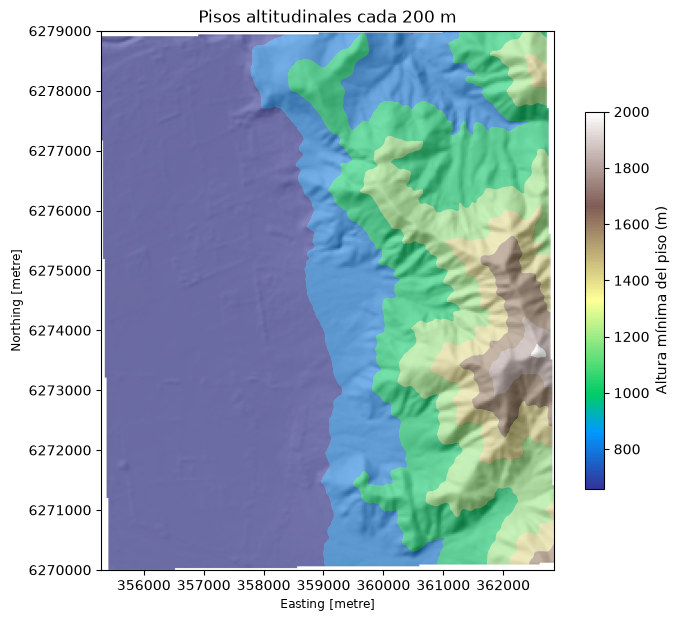

In [20]:
INTERVALO_PISOS = 200     # m

ruta_pisos = CARPETA_SALIDAS / "pisos_altitudinales.gpkg"
if ruta_pisos.exists():
    ruta_pisos.unlink()

ds_dem = gdal.Open(str(RUTA_DEM_UTM))
banda = ds_dem.GetRasterBand(1)
ds_vec = ogr.GetDriverByName("GPKG").CreateDataSource(str(ruta_pisos))
capa = ds_vec.CreateLayer("pisos", srs=ds_dem.GetSpatialRef(), geom_type=ogr.wkbMultiPolygon)
capa.CreateField(ogr.FieldDefn("elev_min", ogr.OFTReal))
capa.CreateField(ogr.FieldDefn("elev_max", ogr.OFTReal))
gdal.ContourGenerateEx(banda, capa, options=[
    f"LEVEL_INTERVAL={INTERVALO_PISOS}", "POLYGONIZE=YES",
    "ELEV_FIELD_MIN=0", "ELEV_FIELD_MAX=1",      # posiciones de los campos, no nombres
    f"NODATA={banda.GetNoDataValue()}",
])
ds_vec = None
ds_dem = None

pisos = gpd.read_file(ruta_pisos)
pisos["rango"] = pisos["elev_min"].astype(int).astype(str) + "–" + pisos["elev_max"].astype(int).astype(str) + " m"
pisos["area_ha"] = pisos.geometry.area / 10_000

tabla_pisos = pisos.groupby("rango", sort=False)["area_ha"].sum().round(1).to_frame()
tabla_pisos["porcentaje"] = (100 * tabla_pisos["area_ha"] / tabla_pisos["area_ha"].sum()).round(1)
display(tabla_pisos)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(sombra, cmap="gray", extent=extension)
pisos.plot(ax=ax, column="elev_min", cmap=TERRENO, alpha=0.55, legend=True,
           legend_kwds={"label": "Altura mínima del piso (m)", "shrink": 0.7})
ax.set_title(f"Pisos altitudinales cada {INTERVALO_PISOS} m")
ax.ticklabel_format(style="plain")
plt.show()

---
## Parte 11. Problemas frecuentes

| Síntoma | Causa probable | Solución |
|---|---|---|
| `HTTP error` o `Timeout` al descargar | Sin internet, proxy institucional o `BBOX` en el océano (no hay tesela) | Revisa la conexión y el `BBOX`. Prueba la Opción C o descarga desde OpenTopography |
| Cientos de curvas apiladas en un borde | Valor NoData no definido (−32768, −9999) | Define `srcNodata=<valor>` en `gdal.Warp` (Parte 4) |
| Longitudes de 0,0003 | El DEM sigue en grados | Usa `RUTA_DEM_UTM`, no el DEM original |
| Las curvas aparecen corridas respecto de la imagen | Las capas están en CRS distintos | Verifica que el DEM y las curvas compartan el CRS (`curvas_gdal.crs`) y usa siempre `RUTA_DEM_UTM` |
| Curvas muy "dentadas" o en escalera | DEM con ruido, o remuestreo *nearest* | Usa remuestreo bilineal, o aumenta `RESOLUCION_M` (una celda mayor generaliza el relieve) |
| Muchísimas curvas pequeñas cerradas | Equidistancia menor que el ruido del DEM | Aumenta `EQUIDISTANCIA` |
| Curvas que "suben" sobre huertos o bosques | El Copernicus DEM es un DSM | Usa un DTM (LiDAR o dron), o interpreta con cautela |
| `files.download` no hace nada | El navegador bloqueó la descarga | Permite las descargas o usa el panel 📁 de Colab |
| Shapefile con nombres de campo cortados | Límite de 10 caracteres del formato | Usa GeoPackage |
| `ModuleNotFoundError: osgeo` | GDAL no instalado en ese entorno | `conda install -c conda-forge gdal` y elige ese kernel |

---
## Ejercicios

1. **Tu propia zona.** Cambia el `BBOX` a un predio o una comuna que conozcas (máx. 10 × 10 km), vuelve a ejecutar todo y entrega el mapa en PDF y el KML. ¿Qué zona UTM se eligió? ¿Coincide con lo esperado?
2. **Sensibilidad a la equidistancia.** Genera curvas con equidistancias de 2, 10, 25 y 50 m. Compara el número de líneas y la longitud total. ¿Con cuál empiezan a aparecer curvas que parecen ruido? Relaciónalo con la exactitud vertical del DEM.
3. **Efecto de la resolución.** Repite el laboratorio con `RESOLUCION_M` = 30, 60 y 90 m, manteniendo la equidistancia. Compara el número de líneas, la longitud total y el aspecto de las curvas en las quebradas. ¿Qué detalle se pierde al aumentar el tamaño de celda? ¿Qué resolución usarías para un mapa de divulgación? ¿Y para diseñar una acequia?
4. **Cota específica.** Un productor quiere saber hasta dónde llegaría un tranque cuya cota de coronamiento es 720 m. Usa la opción `FIXED_LEVELS=720` de `ContourGenerateEx` (en lugar de `LEVEL_INTERVAL`) para trazar solo esa curva y expórtala a KML.
5. **Pisos para una especie.** Usando la Parte 10, calcula qué superficie de la zona queda entre 800 y 1.200 m de altura (por ejemplo, para evaluar una franja de ladera con menor riesgo de heladas por inversión térmica que el fondo del valle). Presenta el resultado en hectáreas y porcentaje.

## Preguntas de reflexión

- ¿Por qué no tiene sentido pedir curvas cada 1 m a un DEM de 30 m, aunque el software las dibuje sin problemas?
- ¿Qué diferencia hay entre un DSM y un DTM? ¿En qué cultivos o situaciones esa diferencia cambia tus conclusiones?
- Si debes entregar las curvas a (a) un topógrafo, (b) un agricultor con celular y (c) un colega de SIG, ¿qué formato le das a cada uno y por qué?
- ¿Qué ventajas tiene leer un COG por partes (Opción B) frente a descargar la tesela completa (Opción C)? ¿Cuándo preferirías la segunda?

## Referencias

- GDAL. [`gdal_contour`](https://gdal.org/en/stable/programs/gdal_contour.html) y [API de Python](https://gdal.org/en/stable/api/python/index.html).
- rasterio. [Documentación](https://rasterio.readthedocs.io/).
- geopandas. [Documentación](https://geopandas.org/).
- ESA / Copernicus. [Copernicus DEM: Product Handbook](https://dataspace.copernicus.eu/explore-data/data-collections/copernicus-contributing-missions/collections-description/COP-DEM).
- AWS Registry of Open Data. [Copernicus DEM](https://registry.opendata.aws/copernicus-dem/).